# 🐍 Python Foundations for AI
## Class 6 — Data Visualization for AI Insights

**Alexandra Oliveira** · AI Engineer  
**Catarina Santos** · AI Engineer

---

<div style="display:flex; align-items:center; gap:24px; margin-bottom:8px;">
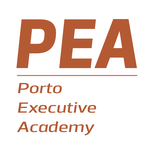
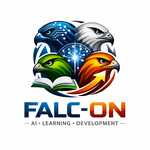
</div>

---

### 📋 What we'll cover today

| # | Topic |
|---|-------|
| 1 | Why visualise? And which chart for which question |
| 2 | matplotlib — your first chart |
| 3 | Labels, legend, grid, and two lines |
| 4 | The four chart types you actually need |
| 5 | Several charts in one figure |
| 6 | Charts straight from a DataFrame |
| 7 | seaborn — nicer charts, less code |
| 8 | 🔗 Capstone — an AI assistant dashboard |

### 🎯 Learning outcomes

By the end of this class you will be able to:

- Choose the right chart for the question you are answering
- Build a chart and label it properly with matplotlib
- Chart a pandas result directly, and use seaborn for quick statistical charts
- Build a dashboard of an AI assistant's performance, and save it for a report

### 🤖 Why charts matter for AI

A table gives exact values. A chart gives **shape**: what is bigger, what is rising, what is unusual.

Every AI product is watched through charts: how many questions arrive each day, which topics leave users unhappy, how consistent the model's answers are. Today you build those charts yourself.

---
## 1. Why Visualise? And Which Chart for Which Question

The chart follows from the **question**, not from taste:

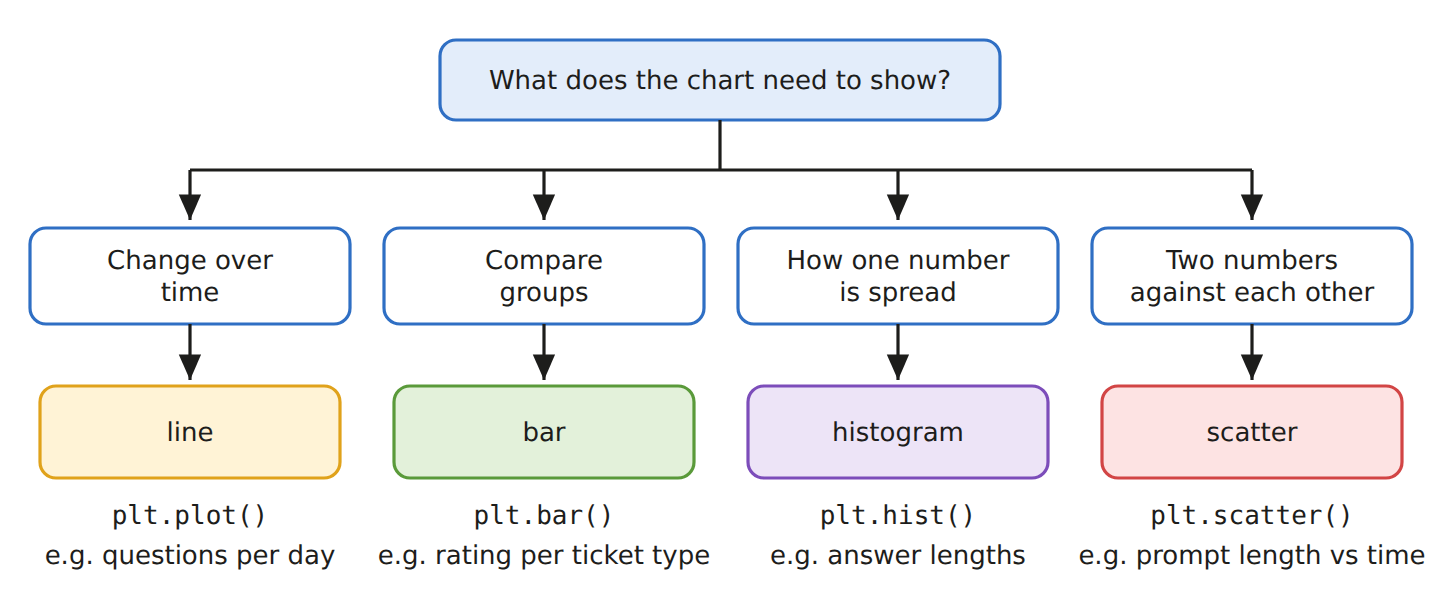

| ❌ A bad chart | ✅ A good chart |
|---------------|----------------|
| No title — the reader has to guess | A title saying what they are looking at |
| Unlabelled axes | Both axes labelled, with units |
| Many colours for no reason | One colour, unless colour *means* something |
| Squeezed, with overlapping labels | A canvas big enough, labels rotated if needed |

> 💡 **Decide the sentence before you draw the chart.** *"Questions rose all week"* tells you: a line chart. If you cannot say the sentence, the chart has no job.

---
## 2. matplotlib — Your First Chart

**matplotlib** is the library every Python chart is built on. It is always imported the same way:

`import matplotlib.pyplot as plt`

Two calls make a chart: `plt.plot(x_values, y_values)` draws a line through the points, and `plt.show()` displays it.

In [ ]:
import matplotlib.pyplot as plt

days = ["Mon", "Tue", "Wed", "Thu", "Fri"]
questions = [42, 38, 55, 61, 70]            # questions FALC-ON AI received each day

In [ ]:
plt.plot(days, questions)
plt.show()

### Styling the line

Keyword arguments — like the ones from Class 4 — change how the line looks:

| Argument | Does |
|----------|------|
| `color="steelblue"` | the line colour, by its name |
| `marker="o"` | a dot at each data point |
| `linestyle="--"` | dashed instead of solid |
| `linewidth=2` | thicker |

Colours are written by **name**, as text. matplotlib knows dozens of them — `"blue"`, `"orange"`, `"green"`, `"red"`, `"grey"`, `"steelblue"`… Today we use `"steelblue"`, and `"orange"` when a second line needs a colour of its own.

> 💡 Instead of a name, you can also give a **colour code**, like `"#2a78d6"`: the exact shade, useful to match a company's brand colours. A name is easier to read, so in this course we use names.

> ⚠️ `plt.show()` also **clears** the figure. Everything that belongs to one chart must be drawn **before** you call it.

In [ ]:
plt.plot(days, questions, color="steelblue", marker="o", linestyle="--", linewidth=2)
plt.show()

---
## 3. Labels, Legend, Grid, and Two Lines

A chart without labels is a puzzle. These calls fix that — all **before** `plt.show()`:

| Call | Adds |
|------|------|
| `plt.figure(figsize=(8, 4))` | a bigger canvas — call it **first** |
| `plt.title("...")` | the title |
| `plt.xlabel("...")` / `plt.ylabel("...")` | the axis labels |
| `plt.grid(True)` | gridlines, to read values more easily |
| `plt.tight_layout()` | fits everything inside the canvas, so no label is cut off — call it **last**, just before `plt.show()` |

In [ ]:
plt.figure(figsize=(8, 4))
plt.plot(days, questions, color="steelblue", marker="o")
plt.title("Questions received this week")
plt.xlabel("Day")
plt.ylabel("Questions")
plt.grid(True)
plt.show()

### Two lines and a legend

Call `plt.plot()` twice before `plt.show()` and both lines land on the same chart. Give each one a `label=`, then call `plt.legend()` so the reader knows which is which.

In [ ]:
last_week = [35, 40, 44, 50, 58]

plt.figure(figsize=(8, 4))
plt.plot(days, questions, color="steelblue", marker="o", label="This week")
plt.plot(days, last_week, color="orange", marker="s", linestyle="--", label="Last week")
plt.title("Questions: this week against last")
plt.xlabel("Day")
plt.ylabel("Questions")
plt.grid(True)
plt.legend()
plt.show()

---
## 4. The Four Chart Types You Actually Need

The same calls every time — only the drawing function changes.

### Bar — compare groups

`plt.bar(names, heights)` draws one bar per group.

In [ ]:
topics = ["classes", "homework", "colab", "exam", "teachers"]
asked = [34, 21, 18, 12, 9]

plt.bar(topics, asked, color="steelblue")
plt.title("Questions per topic")
plt.ylabel("Questions")
plt.show()

### Horizontal bar — for long names

`plt.barh()` is the same with horizontal bars. Long names read easily down the left side, and the axis labels swap over.

In [ ]:
long_topics = ["How many classes", "Homework and deadlines", "Using Google Colab", "Exam and grading", "Who teaches"]

plt.figure(figsize=(8, 4))
plt.barh(long_topics, asked, color="steelblue")
plt.title("Questions per topic")
plt.xlabel("Questions")
plt.tight_layout()                       # keeps the long names inside the canvas
plt.show()

### Histogram — how one number is spread

A histogram takes **one** list of numbers, sorts them into `bins` (ranges of values), and shows how many fell in each. It answers *"are most of these small or large?"*

In [ ]:
# Length, in words, of 24 answers from the assistant
answer_lengths = [18, 22, 25, 27, 28, 30, 31, 33, 34, 35, 36, 38,
                  39, 40, 41, 43, 45, 48, 52, 55, 60, 68, 75, 90]

plt.hist(answer_lengths, bins=6, color="steelblue")
plt.title("How long are the answers?")
plt.xlabel("Answer length (words)")
plt.ylabel("How many answers")
plt.show()

### Scatter — two numbers against each other

One dot per pair of values, no line between them. It answers *"when one grows, does the other grow too?"*

In [ ]:
prompt_words = [5, 8, 12, 15, 20, 25, 30, 40]                # length of the question
seconds = [0.6, 0.8, 1.0, 1.1, 1.4, 1.6, 1.9, 2.4]            # time the model took to answer

plt.scatter(prompt_words, seconds, color="steelblue")
plt.title("Longer questions take longer to answer")
plt.xlabel("Question length (words)")
plt.ylabel("Response time (seconds)")
plt.grid(True)
plt.show()

---
## 5. Several Charts in One Figure

`plt.subplot(rows, columns, position)` splits the canvas into a grid and picks the cell to draw in next. Positions count **left to right, then top to bottom**, starting at 1.

- `plt.figure(figsize=...)` first, or the charts are cramped
- `plt.tight_layout()` last, as in Section 3, so the charts do not overlap

In [ ]:
plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)                     # 1 row, 2 columns: the left one
plt.plot(days, questions, color="steelblue", marker="o")
plt.title("Questions per day")

plt.subplot(1, 2, 2)                     # the right one
plt.bar(topics, asked, color="steelblue")
plt.title("Questions per topic")

plt.tight_layout()
plt.show()

---
## 6. Charts Straight from a DataFrame

In practice, the numbers come out of pandas. We use the support tickets file from Class 3 — upload `support_tickets.csv` to your Colab files space (📁 in the left sidebar) first.

The cell below loads and cleans it with the Class 3 steps.

In [ ]:
import pandas as pd

CSV_PATH = "support_tickets.csv"
tickets = pd.read_csv(CSV_PATH)

tickets = tickets.drop_duplicates()
tickets["Ticket Type"] = tickets["Ticket Type"].str.lower()
tickets = tickets.drop(columns=["Notes", "Customer Name", "Customer Email"])
print(tickets.shape)

A `groupby` or `.value_counts()` result has an **index** (the group names) and **values** (the numbers). You can chart it in two ways:

| Way | Write | When |
|-----|-------|------|
| pandas draws it | `result.plot(kind="bar")` | a quick look while you work |
| matplotlib draws it | `plt.bar(result.index, result.values)` | when you want full control |

In [ ]:
by_type = tickets.groupby("Ticket Type")["Customer Satisfaction Rating"].mean().round(2)
by_type = by_type.sort_values(ascending=False)
print(by_type)

In [ ]:
# The quick way: pandas draws it
by_type.plot(kind="bar", color="steelblue")
plt.title("Average rating per ticket type")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### A reference line

`plt.axhline(y=...)` draws a horizontal line across the whole chart — here, the **overall average**, so the reader sees at once which types are below it.

In [ ]:
# The matplotlib way, with full control
overall = tickets["Customer Satisfaction Rating"].mean().round(2)

plt.figure(figsize=(8, 4))
plt.bar(by_type.index, by_type.values, color="steelblue")
plt.axhline(y=overall, color="grey", linestyle="--")
plt.title("Average rating per ticket type (dashed line: overall average)")
plt.ylabel("Average rating (1 to 5)")
plt.xticks(rotation=20)                  # rotate the names so they do not overlap
plt.tight_layout()
plt.show()

---
## 7. seaborn — Nicer Charts, Less Code

**seaborn** sits on top of matplotlib. It reads a **DataFrame directly** — you name the columns instead of extracting values.

| seaborn call | Draws |
|--------------|-------|
| `sns.countplot(data=df, x="col")` | how many rows per category — it counts for you |
| `sns.set_style("whitegrid")` | a tidy style for every chart after it |

In [ ]:
import seaborn as sns

sns.set_style("whitegrid")

plt.figure(figsize=(7, 4))
sns.countplot(data=tickets, x="Ticket Channel", color="steelblue")
plt.title("Tickets per channel")
plt.show()

| Tool | Use it when |
|------|-------------|
| `result.plot()` | you want a chart in one line while exploring |
| seaborn | you have a DataFrame and want a good chart with little code |
| matplotlib | you want to control every detail, or combine several charts |

---
## 8. 🔗 Capstone — An AI Assistant Dashboard

One figure, four charts, saved to a file you could put in a report. It answers four questions about our support assistant:

| Question | Chart |
|----------|-------|
| Which ticket types leave customers least happy? | horizontal bar |
| How are the ratings spread? | histogram |
| Where do tickets come from? | bar |
| Does a higher **temperature** make answers less consistent? | boxplot |

### Step 1 — The temperature experiment

A model's **temperature** setting controls how much its answers vary: low is focused and consistent, high is more creative and less predictable. We asked the **same question 15 times** at each temperature and measured each answer's length in words.

In [ ]:
low_temp = [58, 61, 60, 57, 62, 59, 60, 63, 58, 61, 60, 59, 62, 60, 61]
high_temp = [45, 72, 60, 38, 81, 55, 66, 49, 120, 58, 74, 41, 63, 52, 110]

print("Average, low temperature: ", round(sum(low_temp) / len(low_temp), 1))
print("Average, high temperature:", round(sum(high_temp) / len(high_temp), 1))

The averages are close. The spread is not — and only a chart shows it: a **boxplot**.

### Reading a boxplot

A boxplot shows how consistent a group of values is:

- the **box** holds the middle half of the values, and the **line** inside is the middle value
- the **whiskers** reach the rest of the normal range
- **dots** beyond the whiskers are **outliers** — unusual values worth a look

It answers *"is this group consistent, or all over the place?"* — which no bar chart of averages can tell you.

`plt.boxplot([list_1, list_2])` draws one box per list, and `plt.xticks([1, 2], [...])` names them.

In [ ]:
plt.boxplot([low_temp, high_temp])
plt.xticks([1, 2], ["Low temperature", "High temperature"])
plt.title("Same question, 15 times: how consistent is the length?")
plt.ylabel("Answer length (words)")
plt.show()

### Step 2 — The numbers for the other three charts

In [ ]:
rated = tickets.dropna(subset=["Customer Satisfaction Rating"])
by_type = rated.groupby("Ticket Type")["Customer Satisfaction Rating"].mean().round(2).sort_values()
by_channel = tickets["Ticket Channel"].value_counts()

### Step 3 — The dashboard, saved as a picture

`plt.savefig("name.png", dpi=150)` saves the figure to a file in the Colab files panel, ready to download. Call it **before** `plt.show()`.

In [ ]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)                                   # top left: happiness per type
plt.barh(by_type.index, by_type.values, color="steelblue")
plt.title("Average rating per ticket type")
plt.xlabel("Average rating (1 to 5)")

plt.subplot(2, 2, 2)                                   # top right: spread of ratings
plt.hist(rated["Customer Satisfaction Rating"], bins=5, color="steelblue")
plt.title("How the ratings are spread")
plt.xlabel("Rating")
plt.ylabel("How many tickets")

plt.subplot(2, 2, 3)                                   # bottom left: where tickets come from
plt.bar(by_channel.index, by_channel.values, color="steelblue")
plt.title("Tickets per channel")
plt.ylabel("Tickets")

plt.subplot(2, 2, 4)                                   # bottom right: the temperature experiment
plt.boxplot([low_temp, high_temp])
plt.xticks([1, 2], ["Low temperature", "High temperature"])
plt.title("Answer length, same question 15 times")
plt.ylabel("Words")

plt.tight_layout()
plt.savefig("assistant_dashboard.png", dpi=150)
plt.show()
print("Saved assistant_dashboard.png")

### 🧠 What the dashboard tells us

- **Refund requests** get the lowest ratings: that is where an AI assistant would help most.
- At **high temperature**, the answers to the same question vary far more — and the two dots far above the box are outliers worth reviewing before they reach a customer.
- The **averages** alone would have hidden that difference. That is why we chart AI output, not just summarise it.

---

### 🎉 That's Class 6!

| Concept | Key syntax |
|---------|------------|
| Bring in matplotlib | `import matplotlib.pyplot as plt` |
| Line | `plt.plot(x, y)` |
| Bar / horizontal bar | `plt.bar(x, heights)`, `plt.barh(names, widths)` |
| Histogram | `plt.hist(values, bins=6)` |
| Scatter | `plt.scatter(x, y)` |
| Style | `color=`, `marker=`, `linestyle=`, `linewidth=` |
| Title and axes | `plt.title()`, `plt.xlabel()`, `plt.ylabel()` |
| Gridlines, legend | `plt.grid(True)`, `label=` then `plt.legend()` |
| Canvas size | `plt.figure(figsize=(8, 4))` |
| Rotate labels | `plt.xticks(rotation=20)` |
| Reference line | `plt.axhline(y=...)` |
| Grid of charts | `plt.subplot(rows, cols, position)`, `plt.tight_layout()` |
| Show / save | `plt.show()`, `plt.savefig("name.png", dpi=150)` |
| From pandas | `result.plot(kind="bar")`, `plt.bar(result.index, result.values)` |
| seaborn | `sns.countplot(data=df, x=...)` |
| Boxplot of lists | `plt.boxplot([list_1, list_2])` |

> 🤖 **The big picture:** You can now show how an AI assistant is doing — where users are unhappy, and how consistent the model is — in one page anyone can read at a glance.

➡️ Now open the **exercises notebook**.